<a href="https://colab.research.google.com/github/suhailahmed2007/ML2/blob/main/SUHAIL_AHMED_MINI_PROJECT_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt # Corrected import
import csv as c
import requests
import gdown

In [ ]:
import re
import gdown
import pandas as pd

url = "https://drive.google.com/file/d/1TXoqikmE0S3LGem8Ig-GktaJJyZPGMgN/view?usp=sharing"
output_file = 'patient_direct.csv'

# Extract file ID from the Google Drive 'view' URL
file_id_match = re.search(r'/d/([a-zA-Z0-9_-]+)', url)

if file_id_match:
    file_id = file_id_match.group(1)
    # Construct the direct download URL
    direct_download_url = f"https://drive.google.com/uc?export=download&id={file_id}"
    print(f"Attempting to download from: {direct_download_url}")

    try:
        gdown.download(direct_download_url, output_file, quiet=False)
        df_patient = pd.read_csv(output_file)
        print(f"Successfully loaded {output_file} into DataFrame.")
        display(df_patient.head())
    except Exception as e:
        print(f"An error occurred during download or reading: {e}")
        # If an error occurs, inspect the downloaded file to understand the content
        print(f"Content of downloaded file '{output_file}':")
        with open(output_file, 'r', encoding='utf-8', errors='ignore') as f:
            for i, line in enumerate(f):
                print(line.strip())
                if i >= 5: # Print first 5 lines for inspection
                    break
else:
    print("Could not extract file ID from the provided URL.")

Attempting to download from: https://drive.google.com/uc?export=download&id=1TXoqikmE0S3LGem8Ig-GktaJJyZPGMgN


Downloading...
From: https://drive.google.com/uc?export=download&id=1TXoqikmE0S3LGem8Ig-GktaJJyZPGMgN
To: /content/patient_direct.csv
100%|██████████| 187k/187k [00:00<00:00, 50.6MB/s]

Successfully loaded patient_direct.csv into DataFrame.


,id,sex,birth_year,country,region,group,infection_reason,infection_order,infected_by,contact_number,confirmed_date,released_date,deceased_date,state
0,1,female,1984.0,China,filtered at airport,NaN,visit to Wuhan,1.0,NaN,45.0,2020-01-20,2020-02-06,NaN,released
1,2,male,1964.0,Korea,filtered at airport,NaN,visit to Wuhan,1.0,NaN,75.0,2020-01-24,2020-02-05,NaN,released
2,3,male,1966.0,Korea,capital area,NaN,visit to Wuhan,1.0,NaN,16.0,2020-01-26,2020-02-12,NaN,released
3,4,male,1964.0,Korea,capital area,NaN,visit to Wuhan,1.0,NaN,95.0,2020-01-27,2020-02-09,NaN,released
4,5,male,1987.0,Korea,capital area,NaN,visit to Wuhan,1.0,NaN,31.0,2020-01-30,NaN,NaN,isolated


In [ ]:
# to add a new column name status
df_patient['status']='isolated'
df_patient.loc[df_patient['released_date'].notna(),'status']='released'
df_patient.loc[df_patient['deceased_date'].notna(),'status']='deceased'
df_patient.head()

,id,sex,birth_year,country,region,group,infection_reason,infection_order,infected_by,contact_number,confirmed_date,released_date,deceased_date,state,status
0,1,female,1984.0,China,filtered at airport,NaN,visit to Wuhan,1.0,NaN,45.0,2020-01-20,2020-02-06,NaN,released,released
1,2,male,1964.0,Korea,filtered at airport,NaN,visit to Wuhan,1.0,NaN,75.0,2020-01-24,2020-02-05,NaN,released,released
2,3,male,1966.0,Korea,capital area,NaN,visit to Wuhan,1.0,NaN,16.0,2020-01-26,2020-02-12,NaN,released,released
3,4,male,1964.0,Korea,capital area,NaN,visit to Wuhan,1.0,NaN,95.0,2020-01-27,2020-02-09,NaN,released,released
4,5,male,1987.0,Korea,capital area,NaN,visit to Wuhan,1.0,NaN,31.0,2020-01-30,NaN,NaN,isolated,isolated


In [ ]:

df_patient['age']=2026-df_patient['birth_year']
df_patient.head()
# Convert date columns to datetime objects
df_patient['confirmed_date'] = pd.to_datetime(df_patient['confirmed_date'])
df_patient['released_date'] = pd.to_datetime(df_patient['released_date'])

df_patient['recovery_timeline']=df_patient['released_date']-df_patient['confirmed_date']
# Convert 'recovery_timeline' to days for numerical plotting
df_patient['recovery_days'] = df_patient['recovery_timeline'].dt.days.fillna(0)
df_patient.head()



df_patient.head()

,id,sex,birth_year,country,region,group,infection_reason,infection_order,infected_by,contact_number,confirmed_date,released_date,deceased_date,state,status,age,recovery_timeline,recovery_days
0,1,female,1984.0,China,filtered at airport,NaN,visit to Wuhan,1.0,NaN,45.0,2020-01-20,2020-02-06,NaN,released,released,42.0,17 days,17.0
1,2,male,1964.0,Korea,filtered at airport,NaN,visit to Wuhan,1.0,NaN,75.0,2020-01-24,2020-02-05,NaN,released,released,62.0,12 days,12.0
2,3,male,1966.0,Korea,capital area,NaN,visit to Wuhan,1.0,NaN,16.0,2020-01-26,2020-02-12,NaN,released,released,60.0,17 days,17.0
3,4,male,1964.0,Korea,capital area,NaN,visit to Wuhan,1.0,NaN,95.0,2020-01-27,2020-02-09,NaN,released,released,62.0,13 days,13.0
4,5,male,1987.0,Korea,capital area,NaN,visit to Wuhan,1.0,NaN,31.0,2020-01-30,NaT,NaN,isolated,isolated,39.0,NaT,0.0


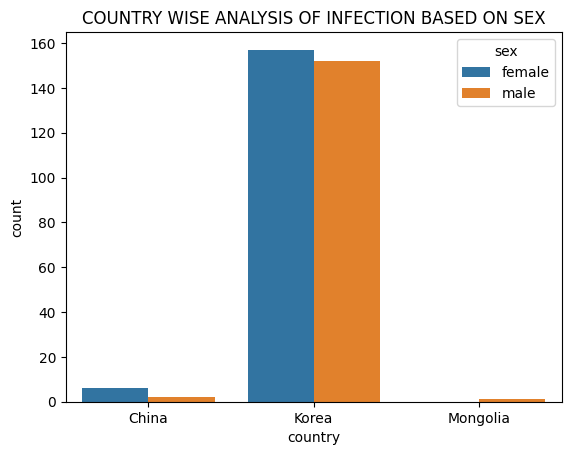

INSIGHTS
--------
There many cases recorded in Korea,that too among Korean women


In [ ]:

sns.countplot(x=df_patient['country'],hue=df_patient['sex'])
plt.title("COUNTRY WISE ANALYSIS OF INFECTION BASED ON SEX")
plt.show()
print('INSIGHTS')
print('--------')
print('There many cases recorded in Korea,that too among Korean women')


Text(0.5, 1.0, 'RECOVERY TIME LINE BASED ON AGE')

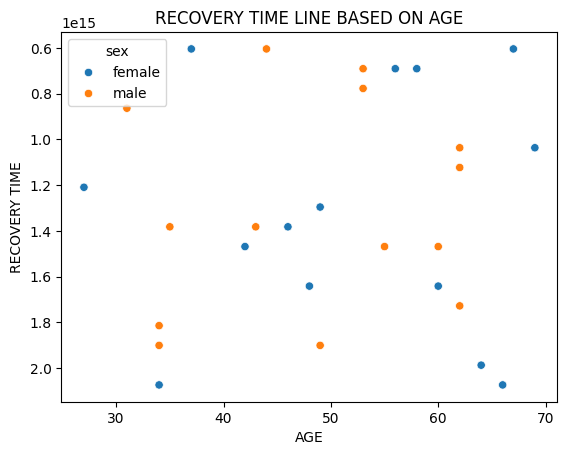

In [ ]:
# Recovery timelines based on age
sns.scatterplot(data=df_patient,x=df_patient['age'],y=df_patient['recovery_timeline'],hue=df_patient['sex'])
plt.xlabel("AGE")
plt.ylabel("RECOVERY TIME")
plt.title("RECOVERY TIME LINE BASED ON AGE")


In [ ]:
# Filter for truly isolated patients and then group by country and sex to count
isolated_counts = df_patient[df_patient['status'] == 'isolated'].groupby(['country','sex'])['sex'].value_counts()
isolated_counts.name = 'isolated_count'

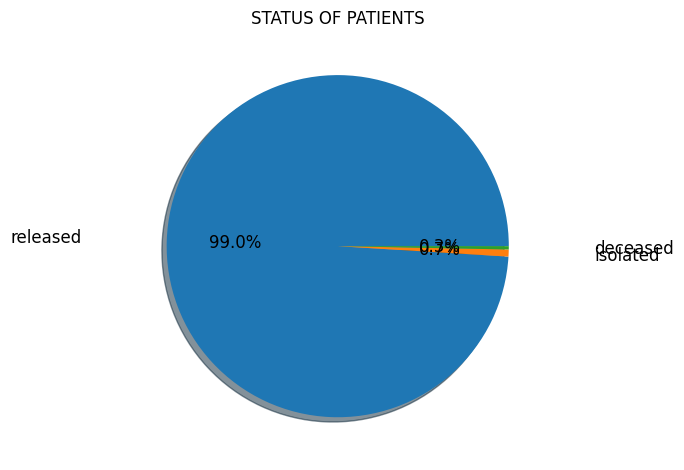

In [ ]:
plt.pie(df_patient['status'].value_counts(),labels=df_patient['status'].unique(),autopct='%1.1f%%',shadow=True,textprops={'fontsize':12},labeldistance=1.5)
plt.title("STATUS OF PATIENTS")
plt.tight_layout()
plt.show()

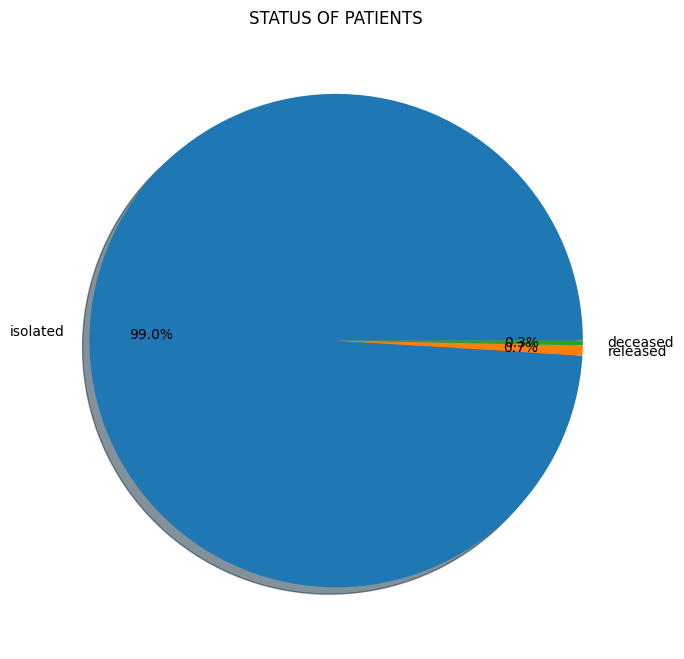

In [ ]:
counts = df_patient['status'].value_counts()

plt.figure(figsize=(7,7))  # slightly bigger figure

plt.pie(
    counts,
    labels=counts.index,
    autopct='%1.1f%%',
    shadow=True,
    textprops={'fontsize': 10},  # reduce font size a bit
    labeldistance=1.1,           # bring labels closer
    pctdistance=0.75             # keep % inside
)

plt.title("STATUS OF PATIENTS")
plt.tight_layout()
plt.show()

In [ ]:
df1=df_patient.groupby(['sex','country'])['recovery_timeline'].mean()
df1

sex     country 
female  China                15 days 18:00:00
        Korea                15 days 00:00:00
male    China                17 days 00:00:00
        Korea      14 days 20:18:27.692307692
        Mongolia                          NaT
Name: recovery_timeline, dtype: timedelta64[ns]

In [ ]:
df1

sex     country 
female  China                15 days 18:00:00
        Korea                15 days 00:00:00
male    China                17 days 00:00:00
        Korea      14 days 20:18:27.692307692
        Mongolia                          NaT
Name: recovery_timeline, dtype: timedelta64[ns]

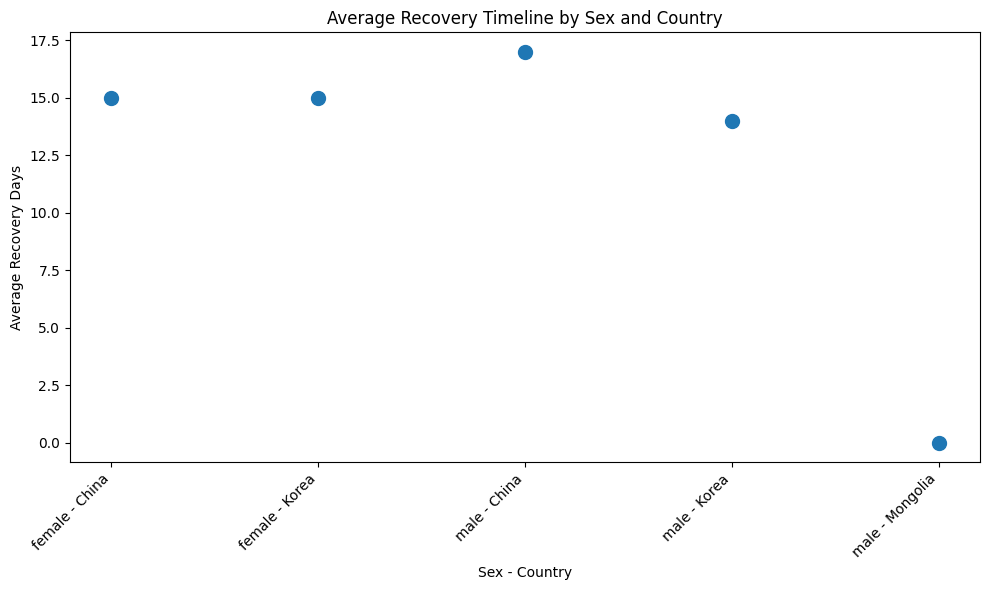

In [ ]:
# Extract average recovery days from df1, converting Timedelta to days
recovery_days_values = df1.dt.days.fillna(0)

# Create combined labels for the x-axis from the MultiIndex
x_labels = [f"{sex} - {country}" for sex, country in df1.index]

# plt.scatter expects numerical x-axis positions for categorical data
x_positions = __builtins__.range(len(x_labels))

plt.figure(figsize=(10, 6))
plt.scatter(x_positions, recovery_days_values, s=100) # Added s for marker size

# Set x-axis ticks and labels
plt.xticks(x_positions, x_labels, rotation=45, ha='right')

plt.xlabel("Sex - Country")
plt.ylabel("Average Recovery Days")
plt.title("Average Recovery Timeline by Sex and Country")
plt.tight_layout() # Adjust layout to prevent labels from overlapping
plt.show()

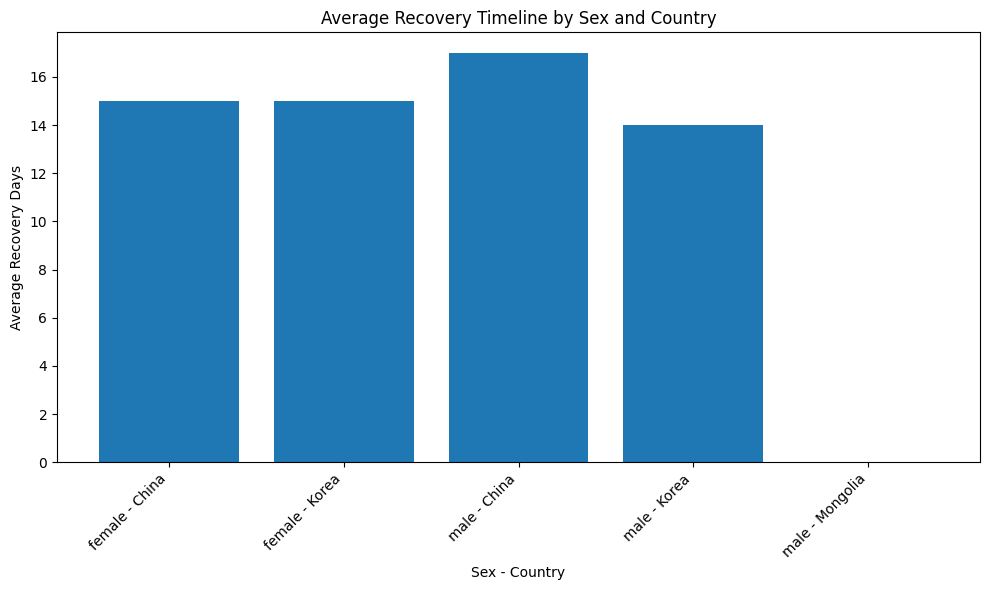

In [ ]:
# Extract values and convert Timedelta to days for plotting
recovery_days = df1.dt.days.fillna(0)

# Extract index levels for labels
sex_labels = df1.index.get_level_values('sex')
country_labels = df1.index.get_level_values('country')

# Combine sex and country for better x-axis labels
combined_labels = [f"{s} - {c}" for s, c in zip(sex_labels, country_labels)]

plt.figure(figsize=(10, 6))
plt.bar(combined_labels, recovery_days)
plt.xlabel("Sex - Country")
plt.ylabel("Average Recovery Days")
plt.title("Average Recovery Timeline by Sex and Country")
plt.xticks(rotation=45, ha='right') # Rotate labels for better readability
plt.tight_layout() # Adjust layout to prevent labels from overlapping
plt.show()

([0, 1, 2, 3, 4],
 [Text(0, 0, 'female - China'),
  Text(1, 0, 'female - Korea'),
  Text(2, 0, 'male - China'),
  Text(3, 0, 'male - Korea'),
  Text(4, 0, 'male - Mongolia')])

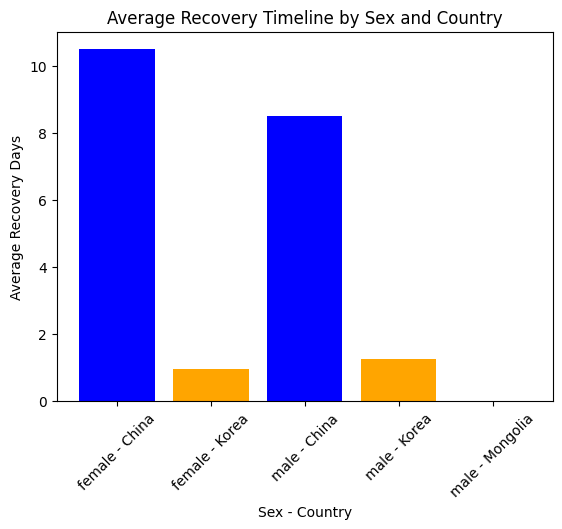

In [ ]:
#recovery time line based on sex and country
recovery_days=df_patient.groupby(['sex','country'])['recovery_days'].mean()
recovery_days.name='recovery_days'
# Extract index levels for labels
sex_labels = recovery_days.index.get_level_values('sex')
country_labels = recovery_days.index.get_level_values('country')

# Combine sex and country for better x-axis labels
combined_labels = [f"{s} - {c}" for s, c in zip(sex_labels, country_labels)]
plt.bar(combined_labels,recovery_days,color=['blue','orange'])# since data_values is dataset on its own and it is derived using functions in pandas library so we make use .get_values

plt.xlabel("Sex - Country")
plt.ylabel("Average Recovery Days")
plt.title("Average Recovery Timeline by Sex and Country")
plt.xticks(rotation=45, )

Text(0.5, 1.0, 'INFECTION COUNT BASED ON AGE')

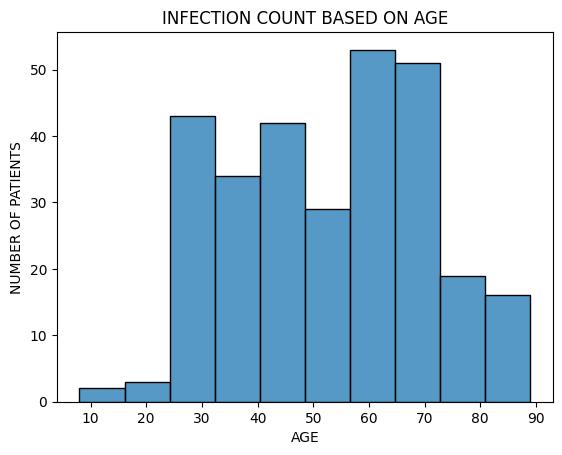

In [ ]:
#infection reason count based on age
sns.histplot(df_patient['age'])
plt.xlabel("AGE")
plt.ylabel("NUMBER OF PATIENTS")
plt.title("INFECTION COUNT BASED ON AGE")

In [ ]:
df1

sex     country 
female  China                15 days 18:00:00
        Korea                15 days 00:00:00
male    China                17 days 00:00:00
        Korea      14 days 20:18:27.692307692
        Mongolia                          NaT
Name: recovery_timeline, dtype: timedelta64[ns]

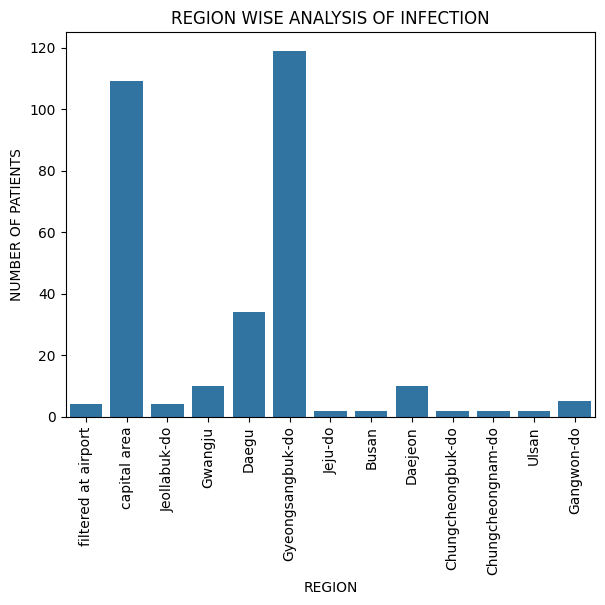

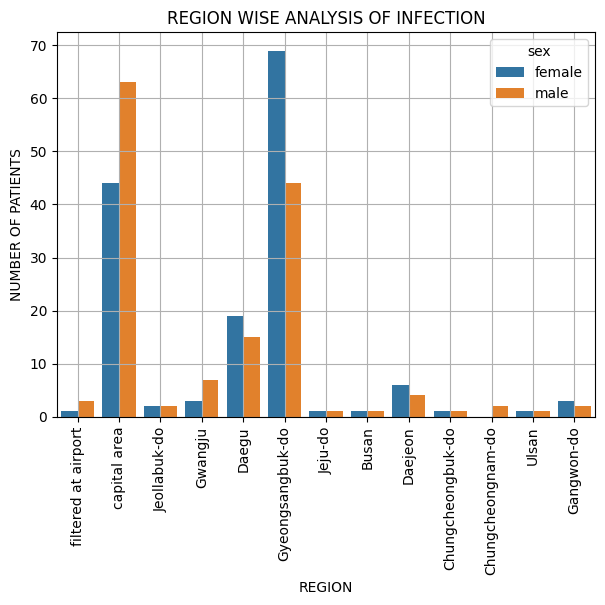

INSIGHTS
--------
From the graphs we can observe that the region with the most observed case is Gyeongsangbuk-do,that too amonng the females


In [ ]:
#GRAPH BASED ON THE COUNT OF PATIENTS IDENTIFIED IN DIFFERENT REGION
sns.countplot(x=df_patient['region'])
plt.title("REGION WISE ANALYSIS OF INFECTION")
plt.xlabel("REGION")

plt.ylabel("NUMBER OF PATIENTS")
plt.tight_layout()
plt.xticks(rotation=90)
plt.show()
sns.countplot(x=df_patient['region'],hue=df_patient['sex'])
plt.title("REGION WISE ANALYSIS OF INFECTION")
plt.xlabel("REGION")
plt.grid()
plt.ylabel("NUMBER OF PATIENTS")
plt.tight_layout()
plt.xticks(rotation=90)
plt.show()
print("INSIGHTS")
print("--------")
print("From the graphs we can observe that the region with the most observed case is Gyeongsangbuk-do,that too amonng the females")


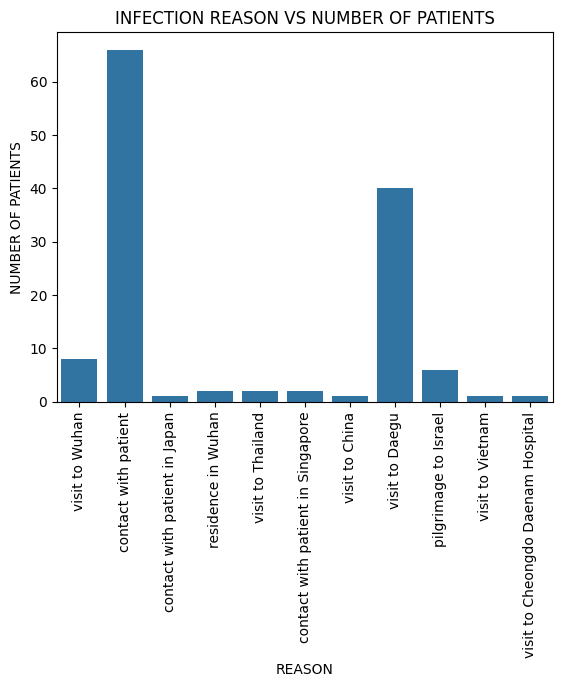

INSIGHTS
--------
There many cases where people are infected due to contact with a patient or a visit to Daegu
Visit to Wuhan has surprisingly lesser number patients.


In [ ]:
sns.countplot(x=df_patient['infection_reason'])
plt.xticks(rotation=90)
plt.title("INFECTION REASON VS NUMBER OF PATIENTS")
plt.xlabel("REASON")
plt.ylabel("NUMBER OF PATIENTS")
plt.show()
print('INSIGHTS')
print('--------')
print('There many cases where people are infected due to contact with a patient or a visit to Daegu')
print("Visit to Wuhan has surprisingly lesser number patients.")

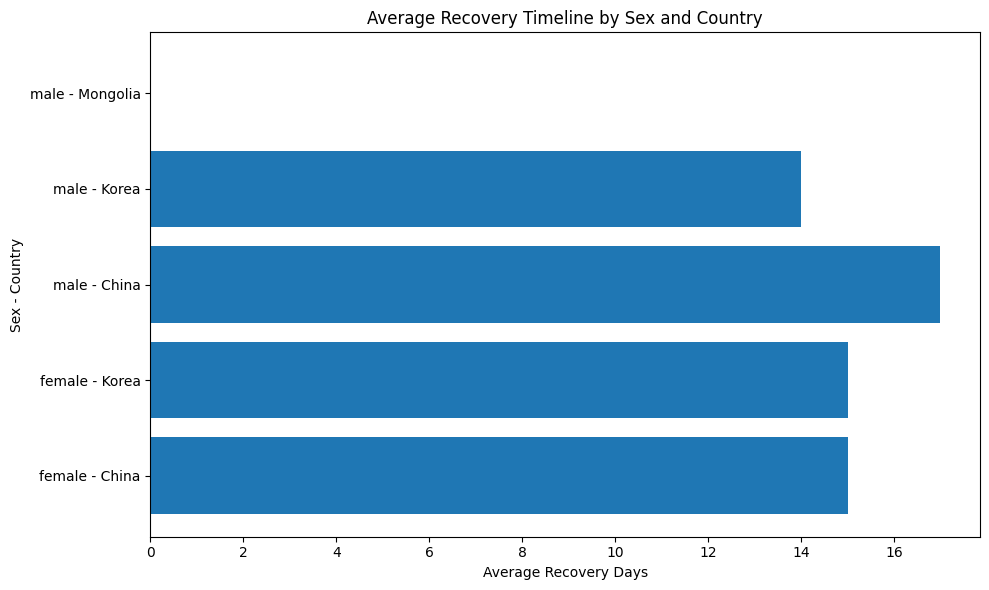

In [ ]:
# Extract values and convert Timedelta to days for plotting
recovery_days = df1.dt.days.fillna(0)

# Extract index levels for labels and combine them
sex_labels = df1.index.get_level_values('sex')
country_labels = df1.index.get_level_values('country')
combined_labels = [f"{s} - {c}" for s, c in zip(sex_labels, country_labels)]

plt.figure(figsize=(10, 6))
plt.barh(combined_labels, recovery_days)
plt.xlabel('Average Recovery Days')
plt.ylabel('Sex - Country')
plt.title('Average Recovery Timeline by Sex and Country')
plt.tight_layout() # Adjust layout to prevent labels from overlapping
plt.show()

Text(0, 0.5, 'RECOVERY DAYS')

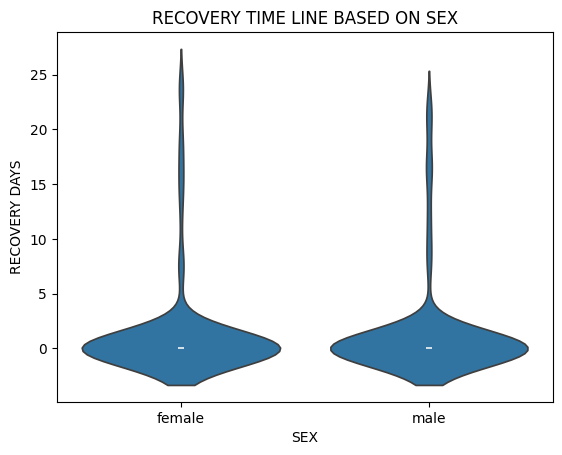

In [ ]:
# Convert 'recovery_timeline' to days for numerical plotting
df_patient['recovery_days'] = df_patient['recovery_timeline'].dt.days.fillna(0)

sns.violinplot(data=df_patient, x='sex', y='recovery_days')
plt.title("RECOVERY TIME LINE BASED ON SEX")
plt.xlabel("SEX")
plt.ylabel("RECOVERY DAYS") # Update label to reflect days

Text(0, 0.5, 'Age')

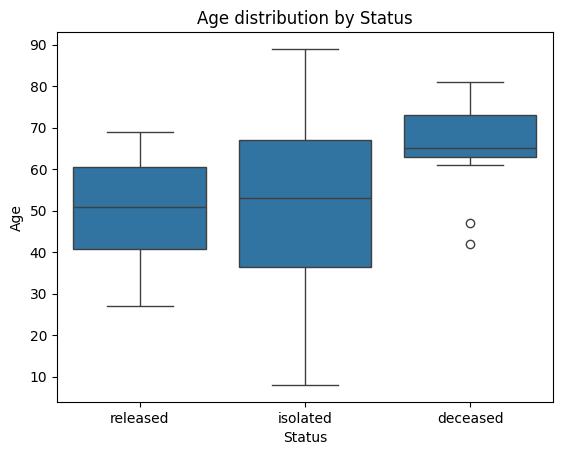

In [ ]:
sns.boxplot(data=df_patient, x='status',y='age')
plt.title('Age distribution by Status')
plt.xlabel('Status')
plt.ylabel('Age')

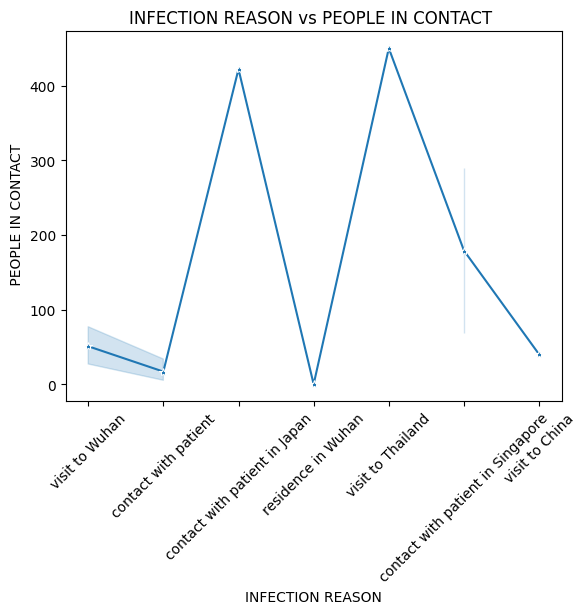

In [ ]:
sns.lineplot(data=df_patient,x='infection_reason',y='contact_number',marker='*')
plt.title("INFECTION REASON vs PEOPLE IN CONTACT ")
plt.xlabel("INFECTION REASON")
plt.ylabel(" PEOPLE IN CONTACT")
plt.xticks(rotation=45)
plt.show()

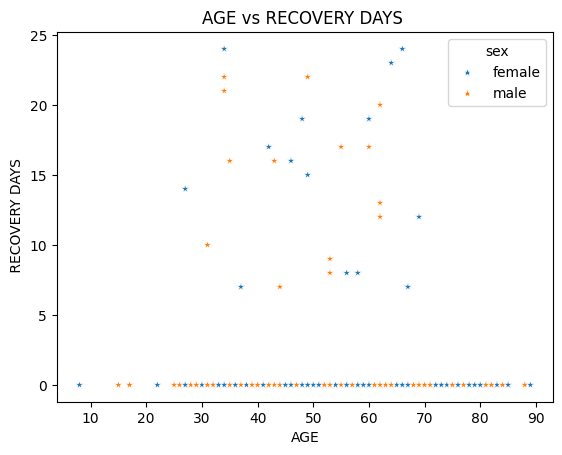

In [ ]:
sns.scatterplot(data=df_patient,x='age',y='recovery_days',marker='*',hue='sex')
plt.title("AGE vs RECOVERY DAYS ")
plt.xlabel("AGE")
plt.ylabel(" RECOVERY DAYS")
plt.xticks(rotation=0)
plt.show()

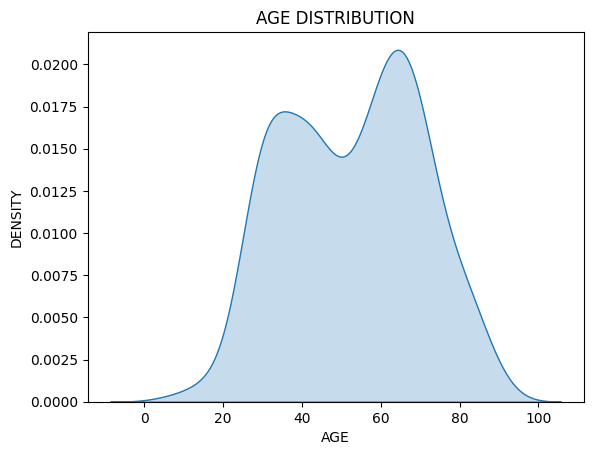

INSIGHTS
--------
There are many patients affected in the age group of 30-70 years.


In [ ]:
sns.kdeplot(df_patient['age'],fill=True)
df_patient['age'].dropna()
from scipy.stats import skew
skewness=skew(df_patient['age'])
plt.title("AGE DISTRIBUTION")
plt.xlabel("AGE")
plt.ylabel("DENSITY")
plt.show()
print("INSIGHTS")
print("--------")
if skewness>0:
  print("There are many young patients infected.")
else:
  print("There are many patients affected in the age group of 30-70 years.")


In [ ]:
df_patient.head()

,id,sex,birth_year,country,region,group,infection_reason,infection_order,infected_by,contact_number,confirmed_date,released_date,deceased_date,state,status,age,recovery_timeline,recovery_days
0,1,female,1984.0,China,filtered at airport,NaN,visit to Wuhan,1.0,NaN,45.0,2020-01-20,2020-02-06,NaN,released,released,42.0,17 days,17.0
1,2,male,1964.0,Korea,filtered at airport,NaN,visit to Wuhan,1.0,NaN,75.0,2020-01-24,2020-02-05,NaN,released,released,62.0,12 days,12.0
2,3,male,1966.0,Korea,capital area,NaN,visit to Wuhan,1.0,NaN,16.0,2020-01-26,2020-02-12,NaN,released,released,60.0,17 days,17.0
3,4,male,1964.0,Korea,capital area,NaN,visit to Wuhan,1.0,NaN,95.0,2020-01-27,2020-02-09,NaN,released,released,62.0,13 days,13.0
4,5,male,1987.0,Korea,capital area,NaN,visit to Wuhan,1.0,NaN,31.0,2020-01-30,NaT,NaN,isolated,isolated,39.0,NaT,0.0


In [ ]:
df_patient['status']='isolated'
df_patient.loc[df_patient['released_date'].notna(),'status']='released'
df_patient.loc[df_patient['deceased_date'].notna(),'status']='deceased'
df_patient.head()

,id,sex,birth_year,country,region,group,infection_reason,infection_order,infected_by,contact_number,confirmed_date,released_date,deceased_date,state,status,age,recovery_timeline,recovery_days
0,1,female,1984.0,China,filtered at airport,NaN,visit to Wuhan,1.0,NaN,45.0,2020-01-20,2020-02-06,NaN,released,released,42.0,17 days,17.0
1,2,male,1964.0,Korea,filtered at airport,NaN,visit to Wuhan,1.0,NaN,75.0,2020-01-24,2020-02-05,NaN,released,released,62.0,12 days,12.0
2,3,male,1966.0,Korea,capital area,NaN,visit to Wuhan,1.0,NaN,16.0,2020-01-26,2020-02-12,NaN,released,released,60.0,17 days,17.0
3,4,male,1964.0,Korea,capital area,NaN,visit to Wuhan,1.0,NaN,95.0,2020-01-27,2020-02-09,NaN,released,released,62.0,13 days,13.0
4,5,male,1987.0,Korea,capital area,NaN,visit to Wuhan,1.0,NaN,31.0,2020-01-30,NaT,NaN,isolated,isolated,39.0,NaT,0.0


In [ ]:
#TO FILTER OUT DATA OF THOSE WHO ARE ALIVE
df2=df_patient[df_patient['status']=='released']
df2.head()

,id,sex,birth_year,country,region,group,infection_reason,infection_order,infected_by,contact_number,confirmed_date,released_date,deceased_date,state,status,age,recovery_timeline,recovery_days
0,1,female,1984.0,China,filtered at airport,NaN,visit to Wuhan,1.0,NaN,45.0,2020-01-20,2020-02-06,NaN,released,released,42.0,17 days,17.0
1,2,male,1964.0,Korea,filtered at airport,NaN,visit to Wuhan,1.0,NaN,75.0,2020-01-24,2020-02-05,NaN,released,released,62.0,12 days,12.0
2,3,male,1966.0,Korea,capital area,NaN,visit to Wuhan,1.0,NaN,16.0,2020-01-26,2020-02-12,NaN,released,released,60.0,17 days,17.0
3,4,male,1964.0,Korea,capital area,NaN,visit to Wuhan,1.0,NaN,95.0,2020-01-27,2020-02-09,NaN,released,released,62.0,13 days,13.0
5,6,male,1964.0,Korea,capital area,NaN,contact with patient,2.0,3.0,17.0,2020-01-30,2020-02-19,NaN,released,released,62.0,20 days,20.0


In [ ]:
print("INSIGHTS INTO RECOVERY DAYS")
recovery_days2=df2.groupby(['country','sex'])['recovery_days'].agg(['mean','median'])
recovery_days2.name='recovery_days'
recovery_days2

INSIGHTS INTO RECOVERY DAYS


mean  median
country sex                      
China   female  15.750000    16.5
        male    17.000000    17.0
Korea   female  15.000000    14.5
        male    14.846154    16.0

In [ ]:
print("TOTAL NUMBER OF PATIENTS FROM EACH COUNTRY")
df_patient.groupby(['country', 'sex']).size()

TOTAL NUMBER OF PATIENTS FROM EACH COUNTRY


country   sex   
China     female      6
          male        2
Korea     female    157
          male      152
Mongolia  male        1
dtype: int64

In [ ]:
print("TOTAL NUMBER OF PATIENTS FROM EACH COUNTRY")
df_patient.groupby('country' ).size()

TOTAL NUMBER OF PATIENTS FROM EACH COUNTRY


,0
country,
China,8
Korea,4203
Mongolia,1


In [ ]:
print("COUNTRY WISE DEATH TOLL")
death_toll = df_patient.groupby(['country','sex'])['deceased_date'].count()
death_toll.name = 'death_toll'#gives a descriptive name
print(death_toll)

COUNTRY WISE DEATH TOLL
country   sex   
China     female    0
          male      0
Korea     female    3
          male      9
Mongolia  male      1
Name: death_toll, dtype: int64


In [ ]:
print("THE COUNTRY WITH THE MOST NUMBER OF CASES")
df_patient['country'].mode()

THE COUNTRY WITH THE MOST NUMBER OF CASES


,country
0,Korea


In [ ]:
# Filter for truly isolated patients and then group by country and sex to count
isolated_counts = df_patient[df_patient['status'] == 'isolated'].groupby(['country','sex'])['sex'].value_counts()
isolated_counts.name = 'isolated_count'# to rename the counts column
print("COUNTRY WISE ISOLATION DATA")
isolated_counts.loc['Mongolia','female']=0
isolated_counts.loc['Mongolia','male']=0
isolated_counts

COUNTRY WISE ISOLATION DATA


country   sex   
China     female      2
          male        1
Korea     female    144
          male      130
Mongolia  female      0
          male        0
Name: isolated_count, dtype: int64

In [ ]:
# Filter for truly recovered patients and then group by country and sex to count
isolated_counts = df_patient[df_patient['status'] == 'released'].groupby(['country','sex'])['sex'].value_counts()
isolated_counts.name = 'total'# to rename the counts column
print("COUNTRY WISE RECOVERY  DATA")
isolated_counts.loc['Mongolia','female']=0
isolated_counts.loc['Mongolia','male']=0
isolated_counts

COUNTRY WISE RECOVERY  DATA


country   sex   
China     female     4
          male       1
Korea     female    10
          male      13
Mongolia  female     0
          male       0
Name: total, dtype: int64

In [ ]:
df_patient.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4212 entries, 0 to 4211
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype          
---  ------             --------------  -----          
 0   id                 4212 non-null   int64          
 1   sex                318 non-null    object         
 2   birth_year         292 non-null    float64        
 3   country            4212 non-null   object         
 4   region             305 non-null    object         
 5   group              76 non-null     object         
 6   infection_reason   130 non-null    object         
 7   infection_order    35 non-null     float64        
 8   infected_by        62 non-null     float64        
 9   contact_number     32 non-null     float64        
 10  confirmed_date     4212 non-null   datetime64[ns] 
 11  released_date      28 non-null     datetime64[ns] 
 12  deceased_date      13 non-null     object         
 13  state              4212 non-null   object       

In [ ]:
print("CORRELATION BETWEEN AGE AND RECOVERY DAYS")
print("__________________________________________")
corr1=df_patient[['age','recovery_days']].corr()
print(corr1)
print("___________________________________________")
print("INSIGHTS")
print("We can observe a very weak negative correlation")
print("The data seems inconsistent as with increase in age there is a decrease in recovery time which is not true")

CORRELATION BETWEEN AGE AND RECOVERY DAYS
__________________________________________
                    age  recovery_days
age            1.000000      -0.055379
recovery_days -0.055379       1.000000
___________________________________________
INSIGHTS
We can observe a very weak negative correlation
The data seems inconsistent as with increase in age there is a decrease in recovery time which is not true


In [ ]:
print("CORRELATION OF INFECTED ORDER AND NUMBER OF PEOPLE IN CONTACT")
print("______________________________________________________________")
corr2=df_patient[['infection_order','contact_number']].corr()
print(corr2)
print("______________________________________________________________")
print("INSIGHTS")
print("We can observe a very weak negative correlation")
print("From this we can observe that infection order doesn't have much influence in the number of conatct. ")

CORRELATION OF INFECTED ORDER AND NUMBER OF PEOPLE IN CONTACT
______________________________________________________________
                 infection_order  contact_number
infection_order          1.00000        -0.09618
contact_number          -0.09618         1.00000
______________________________________________________________
INSIGHTS
We can observe a very weak negative correlation
From this we can observe that infection order doesn't have much influence in the number of conatct. 


In [ ]:
print("Measure of dispersion of recovery days")
print("______________________________________")
range=max(df_patient['recovery_days'])-min(df_patient['recovery_days'])
print("The range of recovery days:",range)
print("The variance of recovery days",df_patient['recovery_days'].var())
print("The standard deviation of recovery days",df_patient['recovery_days'].std())
print("______________________________________")

Measure of dispersion of recovery days
______________________________________
The range of recovery days: 24.0
The variance of recovery days 1.710405896644684
The standard deviation of recovery days 1.307824872314594
______________________________________


In [ ]:
print("INSIGHTS INTO RECOVERY DAYS")
print('-----------------------------')

print("_______________________________________________________________________________________________________________________________________________")
#STANDARD DEVIATION INSIGHTS
mean=df_patient['recovery_days'].mean()
std=df_patient['recovery_days'].std()
var=df_patient['recovery_days'].var()
ratio= std/mean
print("From Standard deviation we can observe that")
if ratio<0.2:
  print("The recovery days are highly consistent with most recovering close to the average.")
elif ratio<0.5:
  print("The recovery days show moderate variation among patient.")
else:
  print("Recovery days are highly spread out,indicating large differences among patients.")
print("__________________________________________________________________________________________________________________________________________________")
  # RANGE INSIGHTS
print("From Range we can observe that")
if range>3*std:
  print("The recovery days are highly spread out,indicating large differences among patients recovery days are larger.")
elif range>1.5*std:
  print("The recovery days show moderate variation among patient.")
else:
  print("The recovery days are highly consistent with most recovering close to the average.")
print("____________________________________________________________________________________________________________________________________________________")
#Variance insights
if var < (0.2 * mean) ** 2:
    print("The low variance indicates that most recovery days are closely clustered around the average, showing consistent recovery patterns among patients.")
elif var< (0.5 * mean) ** 2:
    print("The variance indicates moderate variation in recovery days among patients.")
else:
    print("The high variance indicates that recovery days are widely spread, showing significant differences among patients.")
print("____________________________________________________________________________________________________________________________________________________")
#



INSIGHTS INTO RECOVERY DAYS
-----------------------------
_______________________________________________________________________________________________________________________________________________
From Standard deviation we can observe that
Recovery days are highly spread out,indicating large differences among patients.
__________________________________________________________________________________________________________________________________________________
From Range we can observe that
The recovery days are highly spread out,indicating large differences among patients recovery days are larger.
____________________________________________________________________________________________________________________________________________________
The high variance indicates that recovery days are widely spread, showing significant differences among patients.
__________________________________________________________________________________________________________________________

In [ ]:
df_patient.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4212 entries, 0 to 4211
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype          
---  ------             --------------  -----          
 0   id                 4212 non-null   int64          
 1   sex                318 non-null    object         
 2   birth_year         292 non-null    float64        
 3   country            4212 non-null   object         
 4   region             305 non-null    object         
 5   group              76 non-null     object         
 6   infection_reason   130 non-null    object         
 7   infection_order    35 non-null     float64        
 8   infected_by        62 non-null     float64        
 9   contact_number     32 non-null     float64        
 10  confirmed_date     4212 non-null   datetime64[ns] 
 11  released_date      28 non-null     datetime64[ns] 
 12  deceased_date      13 non-null     object         
 13  state              4212 non-null   object       

In [ ]:
df_patient.head()

,id,sex,birth_year,country,region,group,infection_reason,infection_order,infected_by,contact_number,confirmed_date,released_date,deceased_date,state,status,age,recovery_timeline,recovery_days
0,1,female,1984.0,China,filtered at airport,NaN,visit to Wuhan,1.0,NaN,45.0,2020-01-20,2020-02-06,NaN,released,released,42.0,17 days,17.0
1,2,male,1964.0,Korea,filtered at airport,NaN,visit to Wuhan,1.0,NaN,75.0,2020-01-24,2020-02-05,NaN,released,released,62.0,12 days,12.0
2,3,male,1966.0,Korea,capital area,NaN,visit to Wuhan,1.0,NaN,16.0,2020-01-26,2020-02-12,NaN,released,released,60.0,17 days,17.0
3,4,male,1964.0,Korea,capital area,NaN,visit to Wuhan,1.0,NaN,95.0,2020-01-27,2020-02-09,NaN,released,released,62.0,13 days,13.0
4,5,male,1987.0,Korea,capital area,NaN,visit to Wuhan,1.0,NaN,31.0,2020-01-30,NaT,NaN,isolated,isolated,39.0,NaT,0.0


In [ ]:
df_patient.drop('state',axis=1)

,id,sex,birth_year,country,region,group,infection_reason,infection_order,infected_by,contact_number,confirmed_date,released_date,deceased_date,status,age,recovery_timeline,recovery_days
0,1,female,1984.0,China,filtered at airport,NaN,visit to Wuhan,1.0,NaN,45.0,2020-01-20,2020-02-06,NaN,released,42.0,17 days,17.0
1,2,male,1964.0,Korea,filtered at airport,NaN,visit to Wuhan,1.0,NaN,75.0,2020-01-24,2020-02-05,NaN,released,62.0,12 days,12.0
2,3,male,1966.0,Korea,capital area,NaN,visit to Wuhan,1.0,NaN,16.0,2020-01-26,2020-02-12,NaN,released,60.0,17 days,17.0
3,4,male,1964.0,Korea,capital area,NaN,visit to Wuhan,1.0,NaN,95.0,2020-01-27,2020-02-09,NaN,released,62.0,13 days,13.0
4,5,male,1987.0,Korea,capital area,NaN,visit to Wuhan,1.0,NaN,31.0,2020-01-30,NaT,NaN,isolated,39.0,NaT,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4207,4208,NaN,NaN,Korea,NaN,NaN,NaN,NaN,NaN,NaN,2020-03-01,NaT,NaN,isolated,NaN,NaT,0.0
4208,4209,NaN,NaN,Korea,NaN,NaN,NaN,NaN,NaN,NaN,2020-03-01,NaT,NaN,isolated,NaN,NaT,0.0
4209,4210,NaN,NaN,Korea,NaN,NaN,NaN,NaN,NaN,NaN,2020-03-01,NaT,NaN,isolated,NaN,NaT,0.0
4210,4211,NaN,NaN,Korea,NaN,NaN,NaN,NaN,NaN,NaN,2020-03-01,NaT,NaN,isolated,NaN,NaT,0.0
